**Model A: Transfer-learning classifier**

In [1]:
import sys
import tensorflow as tf

print("Python:", sys.executable)
print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1793127838.934873   54510 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Python: /home/sjainab/anaconda3/envs/tf_midterm/bin/python
TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:2', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:3', device_type='GPU')]


In [2]:
# ================================================================
# 1. IMPORTS, REPRODUCIBILITY, AND GPU SETUP
# ================================================================

import os

# Use physical GPU 1 on the Lambda server
# IMPORTANT: This must be set BEFORE importing TensorFlow
os.environ["CUDA_VISIBLE_DEVICES"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import (
    GlobalAveragePooling2D,
    Dense,
    Dropout
)
from tensorflow.keras.models import Model


# ------------------------------------------------
# Reproducibility
# ------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)


# ------------------------------------------------
# GPU check
# ------------------------------------------------

gpus = tf.config.list_physical_devices("GPU")

print("Visible GPUs:", gpus)

if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)

        print("GPU is ready.")
        print("TensorFlow device:", gpus[0])

    except RuntimeError as e:
        print(e)
else:
    print("WARNING: TensorFlow cannot see a GPU.")

Visible GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:2', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:3', device_type='GPU')]
GPU is ready.
TensorFlow device: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


In [3]:
# ================================================================
# 2. PROJECT AND DATASET PATHS
# ================================================================

PROJECT_DIR = Path.cwd() / "Applied_AI_Midterm"
PROJECT_DIR.mkdir(exist_ok=True)

MODEL_DIR = PROJECT_DIR / "models"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
LOG_DIR = PROJECT_DIR / "logs"

MODEL_DIR.mkdir(exist_ok=True)
CHECKPOINT_DIR.mkdir(exist_ok=True)
LOG_DIR.mkdir(exist_ok=True)


# CHANGE THIS LINE to your actual dataset location
BASE_PATH = Path(
    "/home/sjainab/Downloads/dogs-vs-cats-classification"
)

print("Project directory:", PROJECT_DIR)
print("Dataset exists:", BASE_PATH.exists())

Project directory: /home/sjainab/Assignments AAI/Assignment 3/Applied_AI_Midterm
Dataset exists: True


In [4]:
if BASE_PATH.exists():
    print("\nDataset contents:")
    for item in BASE_PATH.iterdir():
        print(item.name)


Dataset contents:
test
validation
dataset_info.csv
train


In [5]:
# ================================================================
# 3. BUILD ONE DATAFRAME FROM ALL AVAILABLE IMAGES
# ================================================================

def build_dataframe(base_path):

    filepaths = []
    categories = []

    for folder in ["train", "validation", "test"]:

        folder_path = base_path / folder

        if not folder_path.exists():
            continue

        for root, dirs, files in os.walk(folder_path):

            for filename in files:

                if filename.lower().endswith((".jpg", ".jpeg", ".png")):

                    full_path = os.path.join(root, filename)
                    parent_folder = os.path.basename(root).lower()

                    if parent_folder in ["cat", "cats"]:
                        category = "cat"

                    elif parent_folder in ["dog", "dogs"]:
                        category = "dog"

                    else:
                        continue

                    filepaths.append(full_path)
                    categories.append(category)

    df = pd.DataFrame({
        "filename": filepaths,
        "category": categories
    })

    return df


df = build_dataframe(BASE_PATH)

print("Total usable images:", len(df))
print("\nClass distribution:")
print(df["category"].value_counts())

Total usable images: 24930

Class distribution:
category
cat    12472
dog    12458
Name: count, dtype: int64


In [6]:
# ================================================================
# 4. REQUIRED 70% TRAIN / 30% TEST SPLIT
# ================================================================

train_df, test_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["category"]
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Total images:", len(df))
print("Training images:", len(train_df))
print("Testing images:", len(test_df))

print("\nTraining class distribution:")
print(train_df["category"].value_counts())

print("\nTesting class distribution:")
print(test_df["category"].value_counts())

Total images: 24930
Training images: 17451
Testing images: 7479

Training class distribution:
category
cat    8730
dog    8721
Name: count, dtype: int64

Testing class distribution:
category
cat    3742
dog    3737
Name: count, dtype: int64


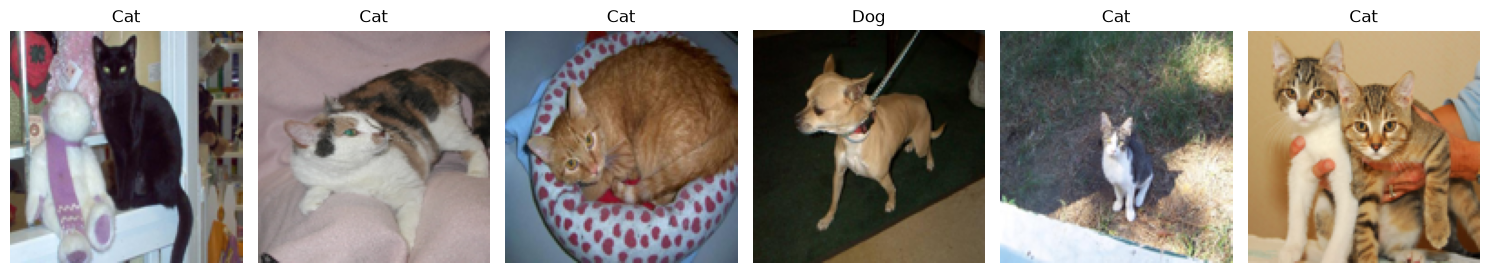

In [7]:
# ================================================================
# 5. DISPLAY ORIGINAL IMAGE SAMPLES
# ================================================================

def display_images(df, num_images=6):

    sample_data = df.sample(
        n=num_images,
        random_state=SEED
    ).reset_index(drop=True)

    fig, axes = plt.subplots(
        1,
        num_images,
        figsize=(15, 4)
    )

    for i, ax in enumerate(axes):

        filename = sample_data.loc[i, "filename"]

        img = Image.open(filename).convert("RGB")
        img = img.resize((128, 128))

        label = sample_data.loc[i, "category"].capitalize()

        ax.imshow(img)
        ax.set_title(label)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


display_images(train_df)

In [8]:
# ================================================================
# 6. PREPROCESSING AND DATA AUGMENTATION
# ================================================================

IMG_SIZE = (128, 128)
BATCH_SIZE = 32


# Training:
# normalization + transformations/augmentation
train_datagen = ImageDataGenerator(

    preprocessing_function=preprocess_input,

    rotation_range=20,
    width_shift_range=0.10,
    height_shift_range=0.10,
    shear_range=0.10,
    zoom_range=0.10,
    horizontal_flip=True,

    fill_mode="nearest"
)


# Testing:
# normalization only
# NO augmentation
test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

In [9]:
# ================================================================
# 7. CREATE TRAINING AND TEST GENERATORS
# ================================================================

train_generator = train_datagen.flow_from_dataframe(

    dataframe=train_df,

    x_col="filename",
    y_col="category",

    directory=None,

    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,

    class_mode="binary",

    shuffle=True,
    seed=SEED
)


test_generator = test_datagen.flow_from_dataframe(

    dataframe=test_df,

    x_col="filename",
    y_col="category",

    directory=None,

    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,

    class_mode="binary",

    shuffle=False
)


print("\nClass mapping:")
print(train_generator.class_indices)

Found 17451 validated image filenames belonging to 2 classes.
Found 7479 validated image filenames belonging to 2 classes.

Class mapping:
{'cat': 0, 'dog': 1}


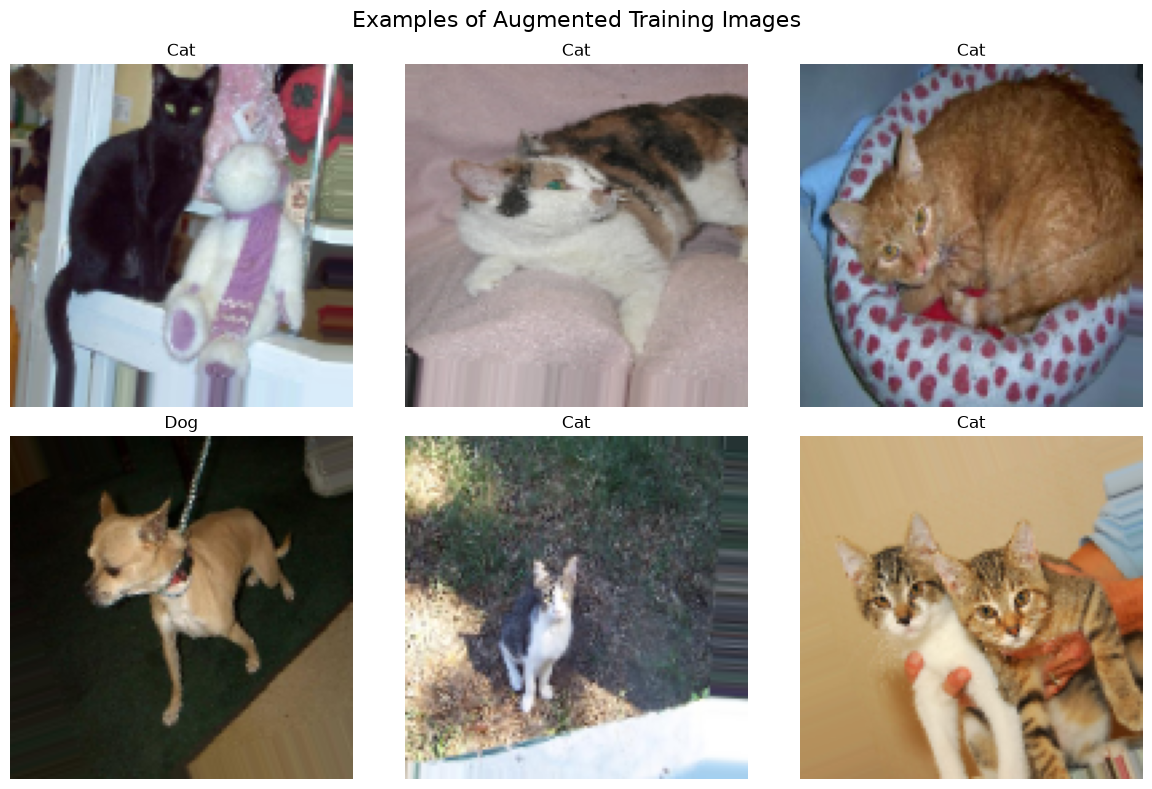

In [10]:
# ================================================================
# 8. VISUALIZE AUGMENTED / TRANSFORMED TRAINING IMAGES
# ================================================================

images, labels = next(train_generator)

plt.figure(figsize=(12, 8))

for i in range(6):

    plt.subplot(2, 3, i + 1)

    # MobileNetV2 preprocessing gives [-1, 1].
    # Convert back to [0, 1] only for visualization.
    display_img = (images[i] + 1.0) / 2.0

    display_img = np.clip(
        display_img,
        0,
        1
    )

    plt.imshow(display_img)

    label = "Dog" if labels[i] == 1 else "Cat"

    plt.title(label)
    plt.axis("off")

plt.suptitle(
    "Examples of Augmented Training Images",
    fontsize=16
)

plt.tight_layout()
plt.show()


# Reset after visualization
train_generator.reset()

In [11]:
# ================================================================
# 9. MODEL A — MOBILENETV2 TRANSFER LEARNING
# ================================================================

base_model_A = MobileNetV2(

    weights="imagenet",

    include_top=False,

    input_shape=(128, 128, 3)
)


# Freeze ImageNet feature extractor initially
base_model_A.trainable = False

I0000 00:00:1793127847.514608   54510 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 12633 MB memory:  -> device: 0, name: NVIDIA RTX A5500, pci bus id: 0000:01:00.0, compute capability: 8.6
I0000 00:00:1793127847.517213   54510 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 22300 MB memory:  -> device: 1, name: NVIDIA RTX A5500, pci bus id: 0000:2b:00.0, compute capability: 8.6
I0000 00:00:1793127847.519736   54510 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:2 with 22302 MB memory:  -> device: 2, name: NVIDIA RTX A5500, pci bus id: 0000:41:00.0, compute capability: 8.6
I0000 00:00:1793127847.522218   54510 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:3 with 22240 MB memory:  -> device: 3, name: NVIDIA RTX A5500, pci bus id: 0000:61:00.0, compute capability: 8.6


In [12]:
# ================================================================
# 10. ADD BINARY CLASSIFIER
# ================================================================

x = base_model_A.output

x = GlobalAveragePooling2D()(x)

x = Dropout(0.3)(x)

x = Dense(
    128,
    activation="relu"
)(x)

output = Dense(
    1,
    activation="sigmoid"
)(x)


model_A = Model(
    inputs=base_model_A.input,
    outputs=output
)

# ================================================================
# 11. COMPILE MODEL A
# ================================================================

model_A.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="binary_crossentropy",

    metrics=["accuracy"]
)


model_A.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 64, 64,    │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 64, 64,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 64, 64,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 64, 64,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 64, 64,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 64, 64,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 65, 65,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 32, 32,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 32, 32,    │      2,304 │ block_1_depthwis

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [13]:
# ================================================================
# 13. TENSORBOARD
# ================================================================

import datetime

log_dir_A = (
    LOG_DIR
    / "model_A_transfer"
    / datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
)

tensorboard_A = tf.keras.callbacks.TensorBoard(

    log_dir=str(log_dir_A),

    histogram_freq=0,

    update_freq="epoch"
)

In [14]:
# ================================================================
# 12. PERIODIC CHECKPOINT SAVING (Save Model A every 5 epochs)
# ================================================================

MODEL_A_CHECKPOINT_DIR = (
    CHECKPOINT_DIR / "model_A_transfer"
)

MODEL_A_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


class SaveEveryNEpochs(tf.keras.callbacks.Callback):

    def __init__(
        self,
        save_dir,
        n=5,
        prefix="model_A"
    ):
        super().__init__()

        self.save_dir = Path(save_dir)
        self.n = n
        self.prefix = prefix

    def on_epoch_end(self, epoch, logs=None):

        epoch_number = epoch + 1

        if epoch_number % self.n == 0:

            save_path = (
                self.save_dir /
                f"{self.prefix}_epoch_{epoch_number:03d}.keras"
            )

            self.model.save(save_path)

            print(
                f"\nCheckpoint saved: {save_path}"
            )


save_model_A = SaveEveryNEpochs(
    MODEL_A_CHECKPOINT_DIR,
    n=5,
    prefix="model_A_transfer"
)

In [15]:
# ================================================================
# 14. TRAIN MODEL A
# ================================================================

TRANSFER_EPOCHS = 10


history_A = model_A.fit(

    train_generator,

    epochs=TRANSFER_EPOCHS,

    callbacks=[
        save_model_A,
        tensorboard_A
    ]
)

Epoch 1/10


I0000 00:00:1793127852.869864   54510 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1793127855.084717   55621 service.cc:153] XLA service 0x7f7fb8036490 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793127855.084753   55621 service.cc:161]   StreamExecutor [0]: NVIDIA RTX A5500, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793127855.084763   55621 service.cc:161]   StreamExecutor [1]: NVIDIA RTX A5500, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793127855.084767   55621 service.cc:161]   StreamExecutor [2]: NVIDIA RTX A5500, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793127855.084771   55621 service.cc:161]   StreamExecutor [3]: NVIDIA RTX A5500, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0

  4/546 ━━━━━━━━━━━━━━━━━━━━ 29s 55ms/step - accuracy: 0.7500 - loss: 0.4873

I0000 00:00:1793127861.362867   55621 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


111/546 ━━━━━━━━━━━━━━━━━━━━ 33s 77ms/step - accuracy: 0.9454 - loss: 0.1409

/home/sjainab/anaconda3/envs/tf_midterm/lib/python3.11/site-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


119/546 ━━━━━━━━━━━━━━━━━━━━ 32s 77ms/step - accuracy: 0.9464 - loss: 0.1375

I0000 00:00:1793127870.999236   55622 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_8125__.115


546/546 ━━━━━━━━━━━━━━━━━━━━ 55s 85ms/step - accuracy: 0.9585 - loss: 0.1097
Epoch 2/10
546/546 ━━━━━━━━━━━━━━━━━━━━ 44s 81ms/step - accuracy: 0.9671 - loss: 0.0863
Epoch 3/10
546/546 ━━━━━━━━━━━━━━━━━━━━ 42s 76ms/step - accuracy: 0.9685 - loss: 0.0773
Epoch 4/10
546/546 ━━━━━━━━━━━━━━━━━━━━ 42s 76ms/step - accuracy: 0.9705 - loss: 0.0755
Epoch 5/10
546/546 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9734 - loss: 0.0699
Checkpoint saved: /home/sjainab/Assignments AAI/Assignment 3/Applied_AI_Midterm/checkpoints/model_A_transfer/model_A_transfer_epoch_005.keras
546/546 ━━━━━━━━━━━━━━━━━━━━ 44s 80ms/step - accuracy: 0.9734 - loss: 0.0699
Epoch 6/10
546/546 ━━━━━━━━━━━━━━━━━━━━ 40s 74ms/step - accuracy: 0.9740 - loss: 0.0700
Epoch 7/10
546/546 ━━━━━━━━━━━━━━━━━━━━ 43s 78ms/step - accuracy: 0.9752 - loss: 0.0646
Epoch 8/10
546/546 ━━━━━━━━━━━━━━━━━━━━ 41s 76ms/step - accuracy: 0.9748 - loss: 0.0623
Epoch 9/10
546/546 ━━━━━━━━━━━━━━━━━━━━ 41s 75ms/step - accuracy: 0.9760 - loss: 0.0620
E

In [24]:
# ================================================================
# 15. FINE-TUNING MODEL A
# ================================================================

base_model_A.trainable = True


# Freeze all but the last 30 MobileNetV2 layers
for layer in base_model_A.layers[:-30]:
    layer.trainable = False


# Keep BatchNormalization layers frozen
for layer in base_model_A.layers:

    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):
        layer.trainable = False


print(
    "Total MobileNetV2 layers:",
    len(base_model_A.layers)
)

print(
    "Trainable MobileNetV2 layers:",
    sum(
        layer.trainable
        for layer in base_model_A.layers
    )
)


# ================================================================
# 16. RECOMPILE FOR FINE-TUNING
# ================================================================

model_A.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),

    loss="binary_crossentropy",

    metrics=["accuracy"]
)

MODEL_A_FT_CHECKPOINT_DIR = (
    CHECKPOINT_DIR / "model_A_finetune"
)

MODEL_A_FT_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


save_model_A_ft = SaveEveryNEpochs(

    MODEL_A_FT_CHECKPOINT_DIR,

    n=5,

    prefix="model_A_finetuned"
)

#Finetuning Tensorboard

log_dir_A_ft = (
    LOG_DIR
    / "model_A_finetune"
    / datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
)

tensorboard_A_ft = tf.keras.callbacks.TensorBoard(

    log_dir=str(log_dir_A_ft),

    histogram_freq=0,

    update_freq="epoch"
)

Total MobileNetV2 layers: 154
Trainable MobileNetV2 layers: 19


In [25]:
# ================================================================
# 18. FINE-TUNE MODEL A
# ================================================================

FINETUNE_EPOCHS = 10

initial_epoch = len(history_A.epoch)


history_A_ft = model_A.fit(

    train_generator,

    initial_epoch=initial_epoch,

    epochs=initial_epoch + FINETUNE_EPOCHS,

    callbacks=[
        save_model_A_ft,
        tensorboard_A_ft
    ]
)

Epoch 11/20


I0000 00:00:1793130829.704326   55623 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_88187__.115


 94/546 ━━━━━━━━━━━━━━━━━━━━ 35s 78ms/step - accuracy: 0.9791 - loss: 0.0511

/home/sjainab/anaconda3/envs/tf_midterm/lib/python3.11/site-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


154/546 ━━━━━━━━━━━━━━━━━━━━ 30s 78ms/step - accuracy: 0.9783 - loss: 0.0515

I0000 00:00:1793130844.973937   55623 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_88187__.115


546/546 ━━━━━━━━━━━━━━━━━━━━ 51s 82ms/step - accuracy: 0.9801 - loss: 0.0519
Epoch 12/20
546/546 ━━━━━━━━━━━━━━━━━━━━ 42s 77ms/step - accuracy: 0.9842 - loss: 0.0437
Epoch 13/20
546/546 ━━━━━━━━━━━━━━━━━━━━ 40s 73ms/step - accuracy: 0.9853 - loss: 0.0414
Epoch 14/20
546/546 ━━━━━━━━━━━━━━━━━━━━ 43s 79ms/step - accuracy: 0.9848 - loss: 0.0407
Epoch 15/20
546/546 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.9855 - loss: 0.0376
Checkpoint saved: /home/sjainab/Assignments AAI/Assignment 3/Applied_AI_Midterm/checkpoints/model_A_finetune/model_A_finetuned_epoch_015.keras
546/546 ━━━━━━━━━━━━━━━━━━━━ 43s 79ms/step - accuracy: 0.9855 - loss: 0.0376
Epoch 16/20
546/546 ━━━━━━━━━━━━━━━━━━━━ 40s 73ms/step - accuracy: 0.9865 - loss: 0.0355
Epoch 17/20
546/546 ━━━━━━━━━━━━━━━━━━━━ 42s 76ms/step - accuracy: 0.9883 - loss: 0.0315
Epoch 18/20
546/546 ━━━━━━━━━━━━━━━━━━━━ 42s 76ms/step - accuracy: 0.9889 - loss: 0.0284
Epoch 19/20
546/546 ━━━━━━━━━━━━━━━━━━━━ 43s 78ms/step - accuracy: 0.9895 - loss:

In [26]:
# ================================================================
# 19. SAVE FINAL MODEL A
# ================================================================

MODEL_A_FINAL_PATH = (
    MODEL_DIR / "Model_A_MobileNetV2_Final.keras"
)

model_A.save(MODEL_A_FINAL_PATH)

print(
    "Final Model A saved to:",
    MODEL_A_FINAL_PATH
)

Final Model A saved to: /home/sjainab/Assignments AAI/Assignment 3/Applied_AI_Midterm/models/Model_A_MobileNetV2_Final.keras


In [27]:
# ================================================================
# 20. FINAL TEST EVALUATION
# ================================================================

test_generator.reset()


model_A_loss, model_A_accuracy = model_A.evaluate(
    test_generator
)


print("\n--- MODEL A FINAL RESULTS ---")

print(
    "Test Loss:",
    model_A_loss
)

print(
    "Test Accuracy:",
    model_A_accuracy
)

234/234 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - accuracy: 0.9807 - loss: 0.0616

--- MODEL A FINAL RESULTS ---
Test Loss: 0.06155969575047493
Test Accuracy: 0.9807460904121399


In [28]:
# ================================================================
# 21. MODEL A CLASSIFICATION METRICS
# ================================================================

test_generator.reset()


y_prob_A = model_A.predict(
    test_generator,
    verbose=1
).ravel()


# Binary predictions
y_pred_A = (
    y_prob_A >= 0.5
).astype(int)


# True labels
y_true = test_generator.classes

234/234 ━━━━━━━━━━━━━━━━━━━━ 10s 35ms/step


In [29]:
model_A_accuracy = accuracy_score(
    y_true,
    y_pred_A
)

model_A_precision = precision_score(
    y_true,
    y_pred_A
)

model_A_recall = recall_score(
    y_true,
    y_pred_A
)

model_A_f1 = f1_score(
    y_true,
    y_pred_A
)

model_A_auc = roc_auc_score(
    y_true,
    y_prob_A
)


print("\n========== MODEL A ==========")

print(
    f"Accuracy : {model_A_accuracy:.4f}"
)

print(
    f"Precision: {model_A_precision:.4f}"
)

print(
    f"Recall   : {model_A_recall:.4f}"
)

print(
    f"F1 Score : {model_A_f1:.4f}"
)

print(
    f"ROC-AUC  : {model_A_auc:.4f}"
)


========== MODEL A ==========
Accuracy : 0.9807
Precision: 0.9825
Recall   : 0.9789
F1 Score : 0.9807
ROC-AUC  : 0.9984


In [30]:
print("\nClassification Report:\n")

print(
    classification_report(
        y_true,
        y_pred_A,
        target_names=["Cat", "Dog"]
    )
)


Classification Report:

              precision    recall  f1-score   support

         Cat       0.98      0.98      0.98      3742
         Dog       0.98      0.98      0.98      3737

    accuracy                           0.98      7479
   macro avg       0.98      0.98      0.98      7479
weighted avg       0.98      0.98      0.98      7479



Model A Confusion Matrix:
[[3677   65]
 [  79 3658]]


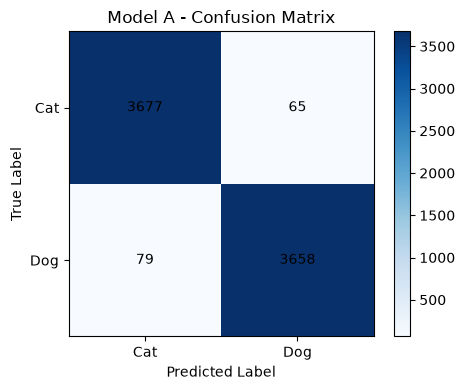

In [31]:
# ================================================================
# 22. CONFUSION MATRIX
# ================================================================

cm_A = confusion_matrix(
    y_true,
    y_pred_A
)

print("Model A Confusion Matrix:")
print(cm_A)

plt.figure(figsize=(5, 4))

plt.imshow(
    cm_A,
    cmap="Blues"
)

plt.title(
    "Model A - Confusion Matrix"
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.xticks(
    [0, 1],
    ["Cat", "Dog"]
)

plt.yticks(
    [0, 1],
    ["Cat", "Dog"]
)


for i in range(2):
    for j in range(2):

        plt.text(
            j,
            i,
            cm_A[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

In [32]:
# ================================================================
# 23. SAVE MODEL A RESULTS
# ================================================================

model_A_results = pd.DataFrame({

    "Model": [
        "Model A - MobileNetV2"
    ],

    "Input": [
        "Original images resized to 128x128"
    ],

    "Accuracy": [
        model_A_accuracy
    ],

    "Precision": [
        model_A_precision
    ],

    "Recall": [
        model_A_recall
    ],

    "F1 Score": [
        model_A_f1
    ],

    "AUC": [
        model_A_auc
    ],

    "Loss": [
        model_A_loss
    ]
})


model_A_results

#Save it
MODEL_A_RESULTS_PATH = (
    PROJECT_DIR / "model_A_results.csv"
)

model_A_results.to_csv(
    MODEL_A_RESULTS_PATH,
    index=False
)

print(
    "Model A results saved to:",
    MODEL_A_RESULTS_PATH
)

Model A results saved to: /home/sjainab/Assignments AAI/Assignment 3/Applied_AI_Midterm/model_A_results.csv


In [33]:
%load_ext tensorboard

In [34]:
%tensorboard --logdir ./Applied_AI_Midterm/logs

**Model B : Same classifier on SRGAN generated images**

In [35]:
# ================================================================
# 24. SRGAN CONFIGURATION
# ================================================================

SR_LR_SIZE = (32, 32)
SR_HR_SIZE = (128, 128)

# Start with 16. If GPU memory allows, you can increase to 32.
SR_BATCH_SIZE = 16

SRGAN_EPOCHS = 150
GENERATOR_PRETRAIN_EPOCHS = 5

SRGAN_DIR = PROJECT_DIR / "srgan"

SRGAN_CHECKPOINT_DIR = SRGAN_DIR / "checkpoints"
SRGAN_MODEL_DIR = SRGAN_DIR / "models"
SRGAN_LOG_DIR = SRGAN_DIR / "logs"

SRGAN_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
SRGAN_MODEL_DIR.mkdir(parents=True, exist_ok=True)
SRGAN_LOG_DIR.mkdir(parents=True, exist_ok=True)

print("SRGAN directory:", SRGAN_DIR)

SRGAN directory: /home/sjainab/Assignments AAI/Assignment 3/Applied_AI_Midterm/srgan


In [68]:
# ================================================================
# 25. CREATE SRGAN DATA PIPELINE
# ================================================================

AUTOTUNE = tf.data.AUTOTUNE

import numpy as np
from PIL import Image, ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True


def load_image_with_pil(path):

    path = path.numpy().decode("utf-8")

    with Image.open(path) as img:

        img = img.convert("RGB")

        image = np.array(
            img,
            dtype=np.float32
        ) / 255.0

    return image

def load_sr_image(image_path, training=False):

    # ------------------------------------------------------------
    # Robust image loading using PIL
    # ------------------------------------------------------------

    image = tf.py_function(
        func=load_image_with_pil,
        inp=[image_path],
        Tout=tf.float32
    )

    # py_function loses shape information,
    # so restore the expected RGB shape
    image.set_shape(
        [None, None, 3]
    )


    # ------------------------------------------------------------
    # HR image = 128 x 128
    # ------------------------------------------------------------

    hr_image = tf.image.resize(
        image,
        SR_HR_SIZE,
        method="bicubic",
        antialias=True
    )


    # ------------------------------------------------------------
    # Data augmentation - training only
    # ------------------------------------------------------------

    if training:

        hr_image = tf.image.random_flip_left_right(
            hr_image
        )

        hr_image = tf.image.random_brightness(
            hr_image,
            max_delta=0.10
        )

        hr_image = tf.image.random_contrast(
            hr_image,
            lower=0.9,
            upper=1.1
        )

        hr_image = tf.clip_by_value(
            hr_image,
            0.0,
            1.0
        )


    # ------------------------------------------------------------
    # LR image = 32 x 32
    # ------------------------------------------------------------

    lr_image = tf.image.resize(
        hr_image,
        SR_LR_SIZE,
        method="bicubic",
        antialias=True
    )


    # ------------------------------------------------------------
    # Normalize [0,1] --> [-1,1]
    # ------------------------------------------------------------

    lr_image = (
        lr_image * 2.0
    ) - 1.0

    hr_image = (
        hr_image * 2.0
    ) - 1.0


    return lr_image, hr_image

In [69]:
def create_sr_dataset(
    dataframe,
    batch_size=16,
    training=False
):

    paths = dataframe["filename"].values

    dataset = tf.data.Dataset.from_tensor_slices(
        paths
    )

    if training:

        dataset = dataset.shuffle(
            len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        lambda x: load_sr_image(
            x,
            training=training
        ),
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(
        batch_size,
        drop_remainder=training
    )

    dataset = dataset.prefetch(
        AUTOTUNE
    )

    return dataset

sr_train_dataset = create_sr_dataset(
    train_df,
    batch_size=SR_BATCH_SIZE,
    training=True
)

sr_test_dataset = create_sr_dataset(
    test_df,
    batch_size=SR_BATCH_SIZE,
    training=False
)

print("SRGAN datasets created.")

SRGAN datasets created.


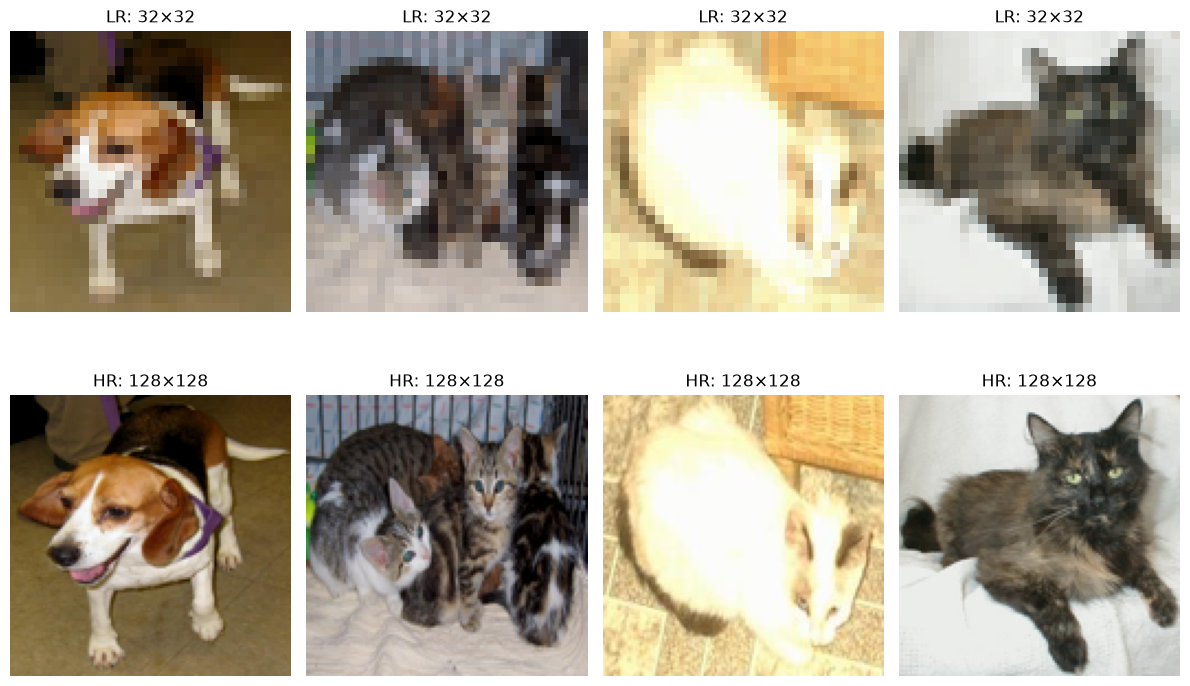

In [70]:
# ================================================================
# 26. VISUALIZE LR AND HR IMAGE PAIRS
# ================================================================

lr_batch, hr_batch = next(
    iter(sr_train_dataset)
)

plt.figure(figsize=(12, 8))

for i in range(4):

    # Convert [-1,1] → [0,1]
    lr_img = (lr_batch[i] + 1.0) / 2.0
    hr_img = (hr_batch[i] + 1.0) / 2.0

    # Low-resolution image
    plt.subplot(2, 4, i + 1)

    plt.imshow(
        tf.clip_by_value(
            lr_img,
            0,
            1
        )
    )

    plt.title("LR: 32×32")
    plt.axis("off")

    # Ground-truth high-resolution image
    plt.subplot(2, 4, i + 5)

    plt.imshow(
        tf.clip_by_value(
            hr_img,
            0,
            1
        )
    )

    plt.title("HR: 128×128")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [71]:
# ================================================================
# 27. SRGAN GENERATOR
# ================================================================


@tf.keras.utils.register_keras_serializable(
    package="SRGAN"
)
class PixelShuffle(tf.keras.layers.Layer):

    def __init__(self, scale=2, **kwargs):
        super().__init__(**kwargs)
        self.scale = scale

    def call(self, inputs):

        return tf.nn.depth_to_space(
            inputs,
            self.scale
        )

    def get_config(self):

        config = super().get_config()

        config.update({
            "scale": self.scale
        })

        return config
    

#Residual Block
def residual_block(x):

    skip = x

    x = layers.Conv2D(
        64,
        kernel_size=3,
        padding="same"
    )(x)

    x = layers.BatchNormalization(
        momentum=0.8
    )(x)

    x = layers.PReLU(
        shared_axes=[1, 2]
    )(x)

    x = layers.Conv2D(
        64,
        kernel_size=3,
        padding="same"
    )(x)

    x = layers.BatchNormalization(
        momentum=0.8
    )(x)

    x = layers.Add()([
        skip,
        x
    ])

    return x


#Upsampling Block
def upsample_block(x):

    x = layers.Conv2D(
        256,
        kernel_size=3,
        padding="same"
    )(x)

    x = PixelShuffle(
        scale=2
    )(x)

    x = layers.PReLU(
        shared_axes=[1, 2]
    )(x)

    return x


#Generator
def build_generator():

    inputs = layers.Input(
        shape=(32, 32, 3)
    )

    # First convolution
    x = layers.Conv2D(
        64,
        kernel_size=9,
        padding="same"
    )(inputs)

    x = layers.PReLU(
        shared_axes=[1, 2]
    )(x)

    long_skip = x


    # ------------------------------------------------------------
    # Residual blocks
    # ------------------------------------------------------------

    for _ in range(8):

        x = residual_block(x)


    x = layers.Conv2D(
        64,
        kernel_size=3,
        padding="same"
    )(x)

    x = layers.BatchNormalization(
        momentum=0.8
    )(x)


    # Global skip connection
    x = layers.Add()([
        x,
        long_skip
    ])


    # ------------------------------------------------------------
    # 32 → 64
    # ------------------------------------------------------------

    x = upsample_block(x)


    # ------------------------------------------------------------
    # 64 → 128
    # ------------------------------------------------------------

    x = upsample_block(x)


    # Output
    outputs = layers.Conv2D(
        3,
        kernel_size=9,
        padding="same",
        activation="tanh"
    )(x)


    return tf.keras.Model(
        inputs,
        outputs,
        name="SRGAN_Generator"
    )

In [72]:
from tensorflow.keras import layers

In [73]:
generator = build_generator()

generator.summary()

Model: "SRGAN_Generator"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_29 (Conv2D)  │ (None, 32, 32,    │     15,616 │ input_layer_6[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_11 (PReLU)  │ (None, 32, 32,    │         64 │ conv2d_29[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_30 (Conv2D)  │ (None, 32, 32,    │     36,928 │ p_re_lu_11[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_30[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_12 (PReLU)  │ (None, 32, 32,    │         64 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_31 (Conv2D)  │ (None, 32, 32,    │     36,928 │ p_re_lu_12[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_31[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_9 (Add)         │ (None, 32, 32,    │          0 │ p_re_lu_11[0][0], │
│                     │ 64)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_32 (Conv2D)  │ (None, 32, 32,    │     36,928 │ add_9[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_32[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ p_re_lu_13 (PReLU)  │ (None, 32, 32,    │         64 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_33 (Conv2D)  │ (None, 32, 32,    │     36,928 │ p_re_lu_13[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_33[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_10 (Add)        │ (None, 32, 32,    │          0 │ add_9[0][0],      │
│                     │ 64)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_34 (Conv2D)  │ (None, 32, 32,    │     36,928 │ add_10[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_34[0][0] 

 Total params: 959,427 (3.66 MB)

 Trainable params: 957,251 (3.65 MB)

 Non-trainable params: 2,176 (8.50 KB)

In [74]:
dummy_lr = tf.zeros(
    (1, 32, 32, 3)
)

dummy_sr = generator(dummy_lr)

print(
    "Generator output shape:",
    dummy_sr.shape
)

Generator output shape: (1, 128, 128, 3)


In [75]:
# ================================================================
# 28. SRGAN DISCRIMINATOR
# ================================================================

def discriminator_block(
    x,
    filters,
    stride=1,
    use_bn=True
):

    x = layers.Conv2D(
        filters,
        kernel_size=3,
        strides=stride,
        padding="same"
    )(x)

    if use_bn:

        x = layers.BatchNormalization(
            momentum=0.8
        )(x)

    x = layers.LeakyReLU(
        negative_slope=0.2
    )(x)

    return x


#Build the generator
def build_discriminator():

    inputs = layers.Input(
        shape=(128, 128, 3)
    )

    x = discriminator_block(
        inputs,
        64,
        stride=1,
        use_bn=False
    )

    x = discriminator_block(
        x,
        64,
        stride=2
    )

    x = discriminator_block(
        x,
        128,
        stride=1
    )

    x = discriminator_block(
        x,
        128,
        stride=2
    )

    x = discriminator_block(
        x,
        256,
        stride=1
    )

    x = discriminator_block(
        x,
        256,
        stride=2
    )

    x = discriminator_block(
        x,
        512,
        stride=1
    )

    x = discriminator_block(
        x,
        512,
        stride=2
    )

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(
        1024
    )(x)

    x = layers.LeakyReLU(
        negative_slope=0.2
    )(x)

    outputs = layers.Dense(
        1
    )(x)


    return tf.keras.Model(
        inputs,
        outputs,
        name="SRGAN_Discriminator"
    )

In [76]:
discriminator = build_discriminator()

discriminator.summary()

Model: "SRGAN_Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_50 (Conv2D)              │ (None, 128, 128, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_9 (LeakyReLU)       │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_51 (Conv2D)              │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_41          │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_10 (LeakyReLU)      │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_52 (Conv2D)              │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_42          │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_11 (LeakyReLU)      │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_53 (Conv2D)              │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_43          │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_12 (LeakyReLU)      │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_54 (Conv2D)              │ (None, 32, 32, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_44          │ (None, 32, 32, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_13 (LeakyReLU)      │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_55 (Conv2D)              │ (None, 16, 16, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_45          │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_14 (LeakyReLU)      │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_56 (Conv2D)              │ (None, 16, 16, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_46          │ (None, 16, 16, 512)    │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_15 (LeakyReLU)      │ (None, 16, 16, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_57 (Conv2D)              │ (None, 8, 8, 512)      │     2,359,80

 Total params: 5,219,137 (19.91 MB)

 Trainable params: 5,215,425 (19.90 MB)

 Non-trainable params: 3,712 (14.50 KB)

In [77]:
# ================================================================
# 29. VGG19 PERCEPTUAL FEATURE EXTRACTOR (To compute the perceptual loss for SRGAN)
# To compare the images at a higher semantic/feature level
# ================================================================

from tensorflow.keras.applications import VGG19
from tensorflow.keras.applications.vgg19 import (
    preprocess_input as vgg19_preprocess
)


vgg19 = VGG19(
    weights="imagenet",
    include_top=False,
    input_shape=(128, 128, 3)
)


# Use high-level VGG feature maps
vgg_features = tf.keras.Model(
    inputs=vgg19.input,
    outputs=vgg19.get_layer(
        "block5_conv4"
    ).output
)


vgg_features.trainable = False

#Convert SRGAN normalized images into VGG input format:

def prepare_for_vgg(image):

    # [-1,1] → [0,255]
    image = (
        image + 1.0
    ) * 127.5

    return vgg19_preprocess(
        image
    )

In [78]:
# ================================================================
# 30. SRGAN LOSSES
# ================================================================

bce = tf.keras.losses.BinaryCrossentropy(
    from_logits=True
)


#Discriminator loss
def discriminator_loss(
    real_logits,
    fake_logits
):

    real_loss = bce(
        tf.ones_like(real_logits),
        real_logits
    )

    fake_loss = bce(
        tf.zeros_like(fake_logits),
        fake_logits
    )

    return (
        real_loss + fake_loss
    ) / 2.0



#3 Generator losses
#Generator Adversarial Loss
def generator_adversarial_loss(
    fake_logits
):

    return bce(
        tf.ones_like(fake_logits),
        fake_logits
    )


#Pixel Loss
def pixel_loss(
    hr,
    sr
):

    return tf.reduce_mean(
        tf.abs(
            hr - sr
        )
    )


#Perceptual loss
def perceptual_loss(
    hr,
    sr
):

    hr_vgg = prepare_for_vgg(
        hr
    )

    sr_vgg = prepare_for_vgg(
        sr
    )

    hr_features = vgg_features(
        hr_vgg,
        training=False
    )

    sr_features = vgg_features(
        sr_vgg,
        training=False
    )

    return tf.reduce_mean(
        tf.square(
            hr_features -
            sr_features
        )
    )

In [79]:
# ================================================================
# 31. SRGAN OPTIMIZERS
# ================================================================

generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-4,
    beta_1=0.9
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=1e-4,
    beta_1=0.9
)


# ================================================================
# 32. GENERATOR PRETRAINING
# ================================================================

@tf.function
def generator_pretrain_step(
    lr_images,
    hr_images
):

    with tf.GradientTape() as tape:

        sr_images = generator(
            lr_images,
            training=True
        )

        loss = tf.reduce_mean(
            tf.square(
                hr_images -
                sr_images
            )
        )

    gradients = tape.gradient(
        loss,
        generator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(
            gradients,
            generator.trainable_variables
        )
    )

    return loss

In [80]:
PRETRAIN_WEIGHTS = (
    SRGAN_MODEL_DIR /
    "generator_pretrained.weights.h5"
)


if PRETRAIN_WEIGHTS.exists():

    print(
        "Pretrained generator found."
    )

    generator.load_weights(
        PRETRAIN_WEIGHTS
    )

else:

    print(
        "Starting generator pretraining..."
    )

    for epoch in range(
        GENERATOR_PRETRAIN_EPOCHS
    ):

        epoch_loss = tf.keras.metrics.Mean()

        for lr_images, hr_images in sr_train_dataset:

            loss = generator_pretrain_step(
                lr_images,
                hr_images
            )

            epoch_loss.update_state(
                loss
            )

        print(
            f"Pretrain Epoch "
            f"{epoch + 1}/"
            f"{GENERATOR_PRETRAIN_EPOCHS} "
            f"- Loss: "
            f"{epoch_loss.result():.5f}"
        )


    generator.save_weights(
        PRETRAIN_WEIGHTS
    )

    print(
        "Pretrained generator saved."
    )

Starting generator pretraining...


/home/sjainab/anaconda3/envs/tf_midterm/lib/python3.11/site-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Pretrain Epoch 1/5 - Loss: 0.02971
Pretrain Epoch 2/5 - Loss: 0.01600
Pretrain Epoch 3/5 - Loss: 0.01410
Pretrain Epoch 4/5 - Loss: 0.01322
Pretrain Epoch 5/5 - Loss: 0.01262
Pretrained generator saved.


In [83]:
# ================================================================
# 33. SRGAN TRAINING STEP
# ================================================================

@tf.function
def srgan_train_step(
    lr_images,
    hr_images
):

    with tf.GradientTape() as gen_tape, \
         tf.GradientTape() as disc_tape:

        # ----------------------------------------
        # Generator prediction
        # ----------------------------------------

        sr_images = generator(
            lr_images,
            training=True
        )


        # ----------------------------------------
        # Discriminator predictions
        # ----------------------------------------

        real_logits = discriminator(
            hr_images,
            training=True
        )

        fake_logits = discriminator(
            sr_images,
            training=True
        )


        # ----------------------------------------
        # Generator losses
        # ----------------------------------------

        p_loss = pixel_loss(
            hr_images,
            sr_images
        )

        perc_loss = perceptual_loss(
            hr_images,
            sr_images
        )

        adv_loss = generator_adversarial_loss(
            fake_logits
        )


        # Combined generator loss
        gen_loss = (
            p_loss
            +
            1e-3 * perc_loss
            +
            1e-3 * adv_loss
        )


        # ----------------------------------------
        # Discriminator loss
        # ----------------------------------------

        disc_loss = discriminator_loss(
            real_logits,
            fake_logits
        )


    # --------------------------------------------
    # Generator update
    # --------------------------------------------

    gen_gradients = gen_tape.gradient(
        gen_loss,
        generator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(
            gen_gradients,
            generator.trainable_variables
        )
    )


    # --------------------------------------------
    # Discriminator update
    # --------------------------------------------

    disc_gradients = disc_tape.gradient(
        disc_loss,
        discriminator.trainable_variables
    )

    discriminator_optimizer.apply_gradients(
        zip(
            disc_gradients,
            discriminator.trainable_variables
        )
    )


    return (
        gen_loss,
        disc_loss,
        p_loss,
        perc_loss,
        adv_loss
    )

In [84]:
# ================================================================
# 34. SRGAN CHECKPOINT SYSTEM
# ================================================================

srgan_checkpoint = tf.train.Checkpoint(

    epoch=tf.Variable(
        0,
        dtype=tf.int64
    ),

    generator=generator,

    discriminator=discriminator,

    generator_optimizer=generator_optimizer,

    discriminator_optimizer=discriminator_optimizer
)


checkpoint_manager = (
    tf.train.CheckpointManager(

        srgan_checkpoint,

        directory=str(
            SRGAN_CHECKPOINT_DIR
        ),

        max_to_keep=10
    )
)


if checkpoint_manager.latest_checkpoint:

    srgan_checkpoint.restore(
        checkpoint_manager.latest_checkpoint
    )

    print(
        "Restored checkpoint:",
        checkpoint_manager.latest_checkpoint
    )

    print(
        "Resume from epoch:",
        int(
            srgan_checkpoint.epoch.numpy()
        )
    )

else:

    print(
        "No SRGAN checkpoint found."
    )

    print(
        "Starting from epoch 0."
    )

No SRGAN checkpoint found.
Starting from epoch 0.


In [85]:
# ================================================================
# 35. SRGAN TENSORBOARD
# ================================================================

import datetime


srgan_log_path = (
    SRGAN_LOG_DIR
    /
    datetime.datetime.now().strftime(
        "%Y%m%d-%H%M%S"
    )
)


srgan_writer = tf.summary.create_file_writer(
    str(srgan_log_path)
)

In [86]:
# ================================================================
# 36. TRAIN SRGAN — 150 EPOCHS (Main Training Cell)
# ================================================================

start_epoch = int(
    srgan_checkpoint.epoch.numpy()
)


for epoch in range(
    start_epoch,
    SRGAN_EPOCHS
):

    gen_metric = tf.keras.metrics.Mean()
    disc_metric = tf.keras.metrics.Mean()

    pixel_metric = tf.keras.metrics.Mean()
    perceptual_metric = tf.keras.metrics.Mean()
    adversarial_metric = tf.keras.metrics.Mean()


    for (
        lr_images,
        hr_images
    ) in sr_train_dataset:

        (
            gen_loss,
            disc_loss,
            p_loss,
            perc_loss,
            adv_loss
        ) = srgan_train_step(
            lr_images,
            hr_images
        )


        gen_metric.update_state(
            gen_loss
        )

        disc_metric.update_state(
            disc_loss
        )

        pixel_metric.update_state(
            p_loss
        )

        perceptual_metric.update_state(
            perc_loss
        )

        adversarial_metric.update_state(
            adv_loss
        )


    # ------------------------------------------------------------
    # TensorBoard
    # ------------------------------------------------------------

    with srgan_writer.as_default():

        tf.summary.scalar(
            "generator_loss",
            gen_metric.result(),
            step=epoch + 1
        )

        tf.summary.scalar(
            "discriminator_loss",
            disc_metric.result(),
            step=epoch + 1
        )

        tf.summary.scalar(
            "pixel_loss",
            pixel_metric.result(),
            step=epoch + 1
        )

        tf.summary.scalar(
            "perceptual_loss",
            perceptual_metric.result(),
            step=epoch + 1
        )

        tf.summary.scalar(
            "adversarial_loss",
            adversarial_metric.result(),
            step=epoch + 1
        )


    print(
        f"Epoch {epoch + 1:03d}/"
        f"{SRGAN_EPOCHS} | "
        f"G: {gen_metric.result():.4f} | "
        f"D: {disc_metric.result():.4f} | "
        f"Pixel: {pixel_metric.result():.4f} | "
        f"Perceptual: "
        f"{perceptual_metric.result():.4f}"
    )


    # Update checkpoint epoch
    srgan_checkpoint.epoch.assign(
        epoch + 1
    )


    # ------------------------------------------------------------
    # Save every 5 epochs
    # ------------------------------------------------------------

    if (epoch + 1) % 5 == 0:

        saved_path = (
            checkpoint_manager.save(
                checkpoint_number=epoch + 1
            )
        )

        print(
            "Checkpoint saved:",
            saved_path
        )

Epoch 001/150 | G: 0.1324 | D: 0.1166 | Pixel: 0.0762 | Perceptual: 51.3622
Epoch 002/150 | G: 0.1258 | D: 0.0634 | Pixel: 0.0735 | Perceptual: 47.0897
Epoch 003/150 | G: 0.1244 | D: 0.0846 | Pixel: 0.0731 | Perceptual: 45.7031
Epoch 004/150 | G: 0.1236 | D: 0.0731 | Pixel: 0.0734 | Perceptual: 44.6206
Epoch 005/150 | G: 0.1214 | D: 0.0235 | Pixel: 0.0715 | Perceptual: 42.6190
Checkpoint saved: /home/sjainab/Assignments AAI/Assignment 3/Applied_AI_Midterm/srgan/checkpoints/ckpt-5
Epoch 006/150 | G: 0.1203 | D: 0.0004 | Pixel: 0.0704 | Perceptual: 41.2399
Epoch 007/150 | G: 0.1198 | D: 0.0002 | Pixel: 0.0698 | Perceptual: 40.3300
Epoch 008/150 | G: 0.1177 | D: 0.0384 | Pixel: 0.0696 | Perceptual: 39.5518
Epoch 009/150 | G: 0.1154 | D: 0.0350 | Pixel: 0.0692 | Perceptual: 38.8519
Epoch 010/150 | G: 0.1146 | D: 0.0375 | Pixel: 0.0690 | Perceptual: 38.3162
Checkpoint saved: /home/sjainab/Assignments AAI/Assignment 3/Applied_AI_Midterm/srgan/checkpoints/ckpt-10
Epoch 011/150 | G: 0.1138 | D

Epoch 086/150 | G: 0.0980 | D: 0.0001 | Pixel: 0.0641 | Perceptual: 24.0733
Epoch 087/150 | G: 0.0992 | D: 0.0478 | Pixel: 0.0666 | Perceptual: 24.6992
Epoch 088/150 | G: 0.0985 | D: 0.1385 | Pixel: 0.0690 | Perceptual: 25.3463
Epoch 089/150 | G: 0.0971 | D: 0.0816 | Pixel: 0.0666 | Perceptual: 24.6275
Epoch 090/150 | G: 0.0973 | D: 0.0793 | Pixel: 0.0668 | Perceptual: 24.5986
Checkpoint saved: /home/sjainab/Assignments AAI/Assignment 3/Applied_AI_Midterm/srgan/checkpoints/ckpt-90
Epoch 091/150 | G: 0.0957 | D: 0.0003 | Pixel: 0.0635 | Perceptual: 23.8143
Epoch 092/150 | G: 0.0965 | D: 0.0199 | Pixel: 0.0650 | Perceptual: 24.0432
Epoch 093/150 | G: 0.0959 | D: 0.0373 | Pixel: 0.0657 | Perceptual: 23.9305
Epoch 094/150 | G: 0.0958 | D: 0.0665 | Pixel: 0.0661 | Perceptual: 24.0392
Epoch 095/150 | G: 0.0958 | D: 0.0658 | Pixel: 0.0662 | Perceptual: 24.1796
Checkpoint saved: /home/sjainab/Assignments AAI/Assignment 3/Applied_AI_Midterm/srgan/checkpoints/ckpt-95
Epoch 096/150 | G: 0.0955 | 

In [87]:
# ================================================================
# 37. SAVE FINAL SRGAN
# ================================================================

generator_path = (
    SRGAN_MODEL_DIR /
    "SRGAN_Generator_Final.keras"
)

discriminator_path = (
    SRGAN_MODEL_DIR /
    "SRGAN_Discriminator_Final.keras"
)


generator.save(
    generator_path
)

discriminator.save(
    discriminator_path
)


print(
    "Generator saved:",
    generator_path
)

print(
    "Discriminator saved:",
    discriminator_path
)

Generator saved: /home/sjainab/Assignments AAI/Assignment 3/Applied_AI_Midterm/srgan/models/SRGAN_Generator_Final.keras
Discriminator saved: /home/sjainab/Assignments AAI/Assignment 3/Applied_AI_Midterm/srgan/models/SRGAN_Discriminator_Final.keras


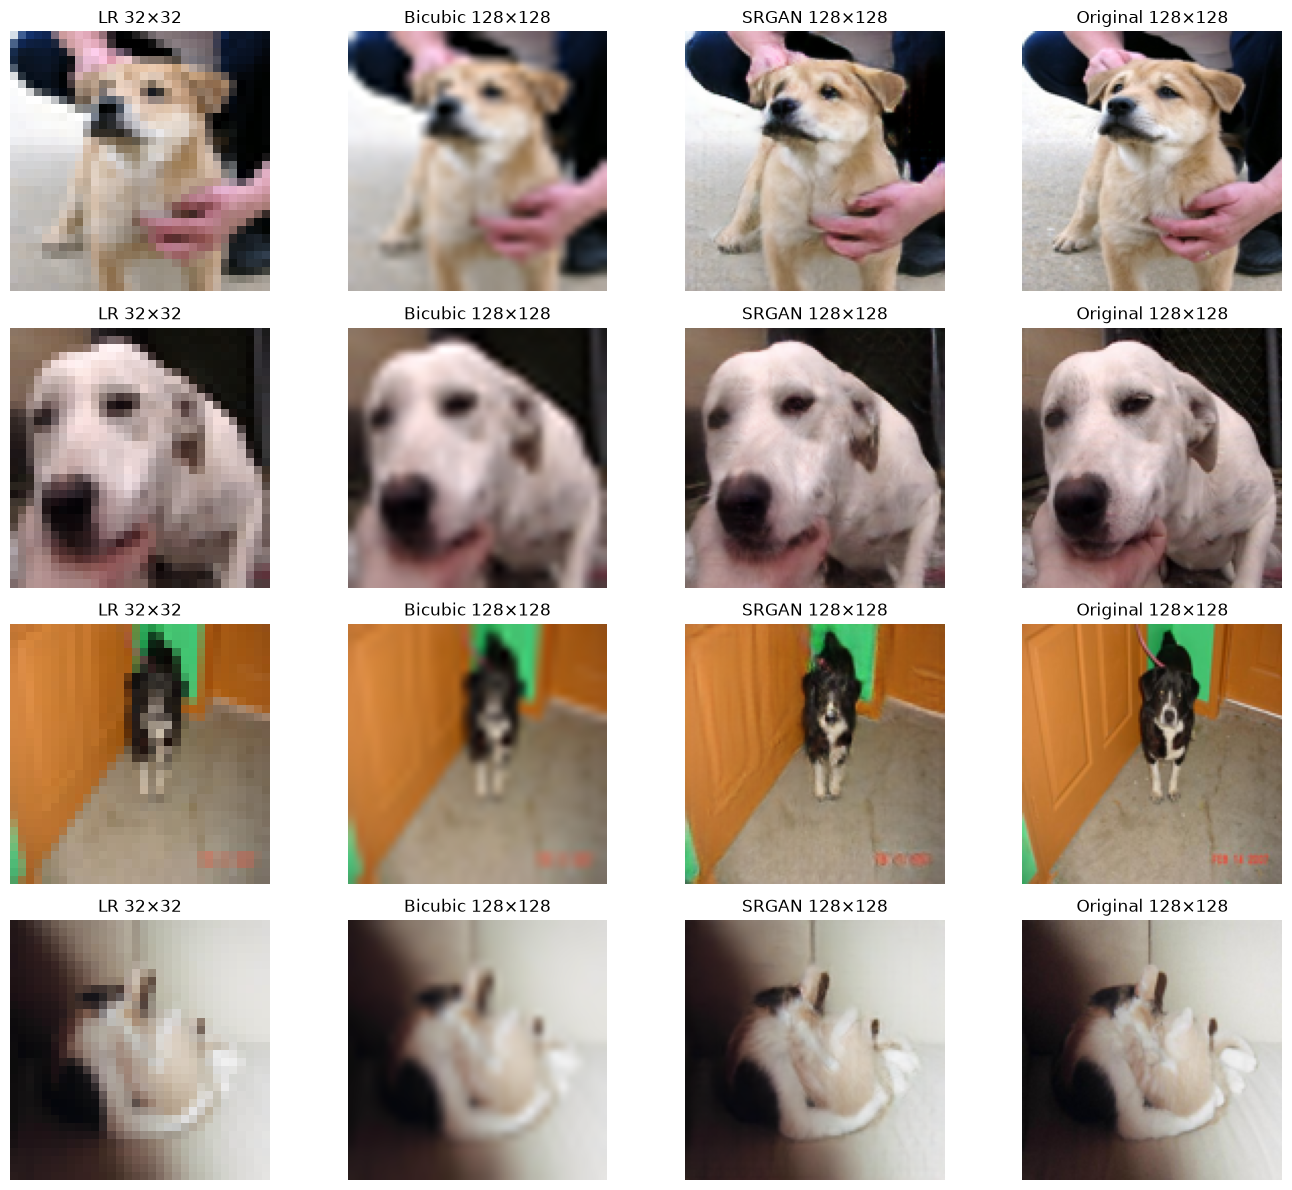

In [88]:
# ================================================================
# 38. VISUALIZE SRGAN RESULTS
# ================================================================

lr_batch, hr_batch = next(
    iter(sr_test_dataset)
)

sr_batch = generator(
    lr_batch,
    training=False
)


plt.figure(
    figsize=(14, 12)
)


for i in range(4):

    lr = (
        lr_batch[i] + 1.0
    ) / 2.0

    hr = (
        hr_batch[i] + 1.0
    ) / 2.0

    sr = (
        sr_batch[i] + 1.0
    ) / 2.0


    bicubic = tf.image.resize(
        lr,
        SR_HR_SIZE,
        method="bicubic"
    )


    # LR
    plt.subplot(
        4,
        4,
        i * 4 + 1
    )

    plt.imshow(
        tf.clip_by_value(
            lr,
            0,
            1
        )
    )

    plt.title("LR 32×32")
    plt.axis("off")


    # Bicubic
    plt.subplot(
        4,
        4,
        i * 4 + 2
    )

    plt.imshow(
        tf.clip_by_value(
            bicubic,
            0,
            1
        )
    )

    plt.title("Bicubic 128×128")
    plt.axis("off")


    # SRGAN
    plt.subplot(
        4,
        4,
        i * 4 + 3
    )

    plt.imshow(
        tf.clip_by_value(
            sr,
            0,
            1
        )
    )

    plt.title("SRGAN 128×128")
    plt.axis("off")


    # Ground truth
    plt.subplot(
        4,
        4,
        i * 4 + 4
    )

    plt.imshow(
        tf.clip_by_value(
            hr,
            0,
            1
        )
    )

    plt.title("Original 128×128")
    plt.axis("off")


plt.tight_layout()
plt.show()

In [95]:
# ================================================================
# 39. GENERATE SRGAN DATASET FOR MODEL B
# ================================================================

SR_GENERATED_DIR = (
    PROJECT_DIR /
    "srgan_generated"
)

SR_TRAIN_DIR = (
    SR_GENERATED_DIR /
    "train"
)

SR_TEST_DIR = (
    SR_GENERATED_DIR /
    "test"
)


for split_dir in [
    SR_TRAIN_DIR,
    SR_TEST_DIR
]:

    (
        split_dir / "cat"
    ).mkdir(
        parents=True,
        exist_ok=True
    )

    (
        split_dir / "dog"
    ).mkdir(
        parents=True,
        exist_ok=True
    )
    

# ================================================================
# GENERATE SRGAN DATASET FOR MODEL B
# Robust version using PIL
# ================================================================

def generate_sr_dataframe(
    dataframe,
    output_root,
    generator_model,
    batch_size=32
):

    dataframe = dataframe.reset_index(drop=True)

    generated_records = []

    for start in range(
        0,
        len(dataframe),
        batch_size
    ):

        batch_df = dataframe.iloc[
            start:start + batch_size
        ]

        lr_images = []

        # --------------------------------------------------------
        # Load each image safely with PIL
        # --------------------------------------------------------
        for path in batch_df["filename"]:

            with Image.open(path) as img:

                # Force all images to standard RGB
                img = img.convert("RGB")

                image = np.array(
                    img,
                    dtype=np.float32
                ) / 255.0

            # Convert NumPy array to TensorFlow tensor
            image = tf.convert_to_tensor(
                image,
                dtype=tf.float32
            )

            # ----------------------------------------------------
            # HR reference size = 128x128
            # ----------------------------------------------------
            image = tf.image.resize(
                image,
                SR_HR_SIZE,
                method="bicubic",
                antialias=True
            )

            # ----------------------------------------------------
            # Downscale to LR = 32x32
            # ----------------------------------------------------
            lr = tf.image.resize(
                image,
                SR_LR_SIZE,
                method="bicubic",
                antialias=True
            )

            # Normalize [0,1] -> [-1,1]
            lr = (lr * 2.0) - 1.0

            lr_images.append(lr)


        # --------------------------------------------------------
        # Combine images into one batch
        # --------------------------------------------------------
        lr_images = tf.stack(
            lr_images
        )


        # --------------------------------------------------------
        # SRGAN generates 128x128 images
        # --------------------------------------------------------
        sr_images = generator_model(
            lr_images,
            training=False
        )


        # --------------------------------------------------------
        # Convert SRGAN output [-1,1] -> [0,255]
        # --------------------------------------------------------
        sr_images = (
            sr_images + 1.0
        ) / 2.0

        sr_images = tf.clip_by_value(
            sr_images,
            0,
            1
        )

        sr_images = (
            sr_images * 255.0
        ).numpy().astype(
            np.uint8
        )


        # --------------------------------------------------------
        # Save generated images
        # --------------------------------------------------------
        for local_idx, (_, row) in enumerate(
            batch_df.iterrows()
        ):

            category = row["category"]

            original_name = Path(
                row["filename"]
            ).stem

            output_path = (
                output_root
                / category
                / f"{start + local_idx:06d}_{original_name}.jpg"
            )


            Image.fromarray(
                sr_images[local_idx]
            ).save(
                output_path,
                quality=95
            )


            generated_records.append({

                "filename": str(
                    output_path
                ),

                "category": category
            })


        # --------------------------------------------------------
        # Progress
        # --------------------------------------------------------
        if (
            start // batch_size
        ) % 20 == 0:

            print(
                f"Generated "
                f"{min(start + batch_size, len(dataframe))}"
                f"/{len(dataframe)}"
            )


    return pd.DataFrame(
        generated_records
    )

In [96]:
#Generate training images
sr_train_df = generate_sr_dataframe(

    train_df,

    SR_TRAIN_DIR,

    generator,

    batch_size=32
)

#Generate test images
sr_test_df = generate_sr_dataframe(

    test_df,

    SR_TEST_DIR,

    generator,

    batch_size=32
)

print(
    "Model B training images:",
    len(sr_train_df)
)

print(
    "Model B testing images:",
    len(sr_test_df)
)


print(
    "\nTraining classes:"
)

print(
    sr_train_df[
        "category"
    ].value_counts()
)

Generated 32/17451
Generated 672/17451
Generated 1312/17451
Generated 1952/17451
Generated 2592/17451
Generated 3232/17451
Generated 3872/17451
Generated 4512/17451
Generated 5152/17451
Generated 5792/17451
Generated 6432/17451
Generated 7072/17451
Generated 7712/17451
Generated 8352/17451
Generated 8992/17451
Generated 9632/17451


/home/sjainab/anaconda3/envs/tf_midterm/lib/python3.11/site-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Generated 10272/17451
Generated 10912/17451
Generated 11552/17451
Generated 12192/17451
Generated 12832/17451
Generated 13472/17451
Generated 14112/17451
Generated 14752/17451
Generated 15392/17451
Generated 16032/17451
Generated 16672/17451
Generated 17312/17451
Generated 32/7479
Generated 672/7479
Generated 1312/7479
Generated 1952/7479
Generated 2592/7479
Generated 3232/7479
Generated 3872/7479
Generated 4512/7479
Generated 5152/7479
Generated 5792/7479
Generated 6432/7479
Generated 7072/7479
Model B training images: 17451
Model B testing images: 7479

Training classes:
category
cat    8730
dog    8721
Name: count, dtype: int64


In [97]:
#Generate training images
sr_train_df = generate_sr_dataframe(

    train_df,

    SR_TRAIN_DIR,

    generator,

    batch_size=32
)

#Generate test images
sr_test_df = generate_sr_dataframe(

    test_df,

    SR_TEST_DIR,

    generator,

    batch_size=32
)

print(
    "Model B training images:",
    len(sr_train_df)
)

print(
    "Model B testing images:",
    len(sr_test_df)
)


print(
    "\nTraining classes:"
)

print(
    sr_train_df[
        "category"
    ].value_counts()
)

Generated 32/17451
Generated 672/17451
Generated 1312/17451
Generated 1952/17451
Generated 2592/17451
Generated 3232/17451
Generated 3872/17451
Generated 4512/17451
Generated 5152/17451
Generated 5792/17451
Generated 6432/17451
Generated 7072/17451
Generated 7712/17451
Generated 8352/17451
Generated 8992/17451
Generated 9632/17451


/home/sjainab/anaconda3/envs/tf_midterm/lib/python3.11/site-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Generated 10272/17451
Generated 10912/17451
Generated 11552/17451
Generated 12192/17451
Generated 12832/17451
Generated 13472/17451
Generated 14112/17451
Generated 14752/17451
Generated 15392/17451
Generated 16032/17451
Generated 16672/17451
Generated 17312/17451
Generated 32/7479
Generated 672/7479
Generated 1312/7479
Generated 1952/7479
Generated 2592/7479
Generated 3232/7479
Generated 3872/7479
Generated 4512/7479
Generated 5152/7479
Generated 5792/7479
Generated 6432/7479
Generated 7072/7479
Model B training images: 17451
Model B testing images: 7479

Training classes:
category
cat    8730
dog    8721
Name: count, dtype: int64


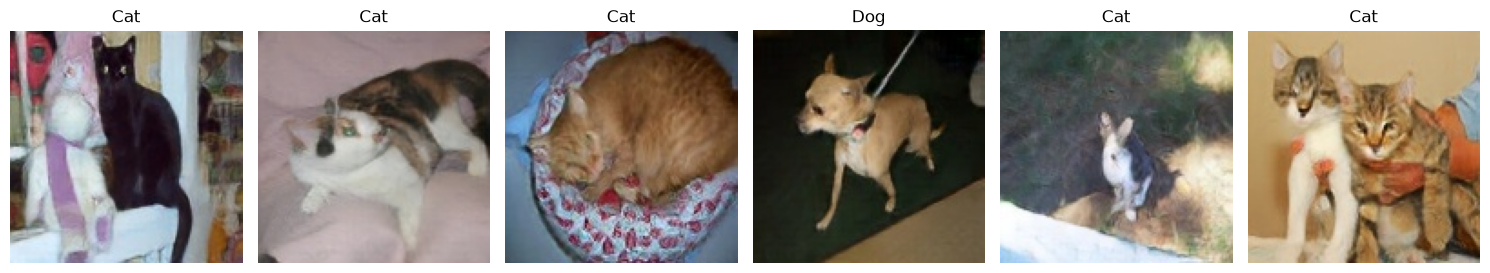

In [98]:
# ================================================================
# 40. DISPLAY SRGAN-GENERATED IMAGES
# ================================================================

display_images(
    sr_train_df,
    num_images=6
)

In [99]:
# ================================================================
# 41. MODEL B DATA LOADERS
# ================================================================

train_datagen_B = ImageDataGenerator(

    preprocessing_function=preprocess_input,

    rotation_range=20,
    width_shift_range=0.10,
    height_shift_range=0.10,
    shear_range=0.10,
    zoom_range=0.10,
    horizontal_flip=True,

    fill_mode="nearest"
)


test_datagen_B = ImageDataGenerator(
    preprocessing_function=preprocess_input
)


#CREATE GENERATORS
train_generator_B = (
    train_datagen_B.flow_from_dataframe(

        dataframe=sr_train_df,

        x_col="filename",
        y_col="category",

        directory=None,

        target_size=(
            128,
            128
        ),

        batch_size=32,

        class_mode="binary",

        shuffle=True,

        seed=SEED
    )
)


test_generator_B = (
    test_datagen_B.flow_from_dataframe(

        dataframe=sr_test_df,

        x_col="filename",
        y_col="category",

        directory=None,

        target_size=(
            128,
            128
        ),

        batch_size=32,

        class_mode="binary",

        shuffle=False
    )
)


print(
    train_generator_B.class_indices
)

Found 17451 validated image filenames belonging to 2 classes.
Found 7479 validated image filenames belonging to 2 classes.
{'cat': 0, 'dog': 1}


In [100]:
# ================================================================
# 42. MODEL B — SAME MOBILENETV2 ARCHITECTURE
# ================================================================

base_model_B = MobileNetV2(

    weights="imagenet",

    include_top=False,

    input_shape=(
        128,
        128,
        3
    )
)


base_model_B.trainable = False


x = base_model_B.output

x = GlobalAveragePooling2D()(x)

x = Dropout(
    0.3
)(x)

x = Dense(
    128,
    activation="relu"
)(x)

output = Dense(
    1,
    activation="sigmoid"
)(x)


model_B = Model(
    inputs=base_model_B.input,
    outputs=output
)

In [101]:
model_B.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="binary_crossentropy",

    metrics=["accuracy"]
)


model_B.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_9       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 64, 64,    │        864 │ input_layer_9[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 64, 64,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 64, 64,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 64, 64,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 64, 64,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 64, 64,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 65, 65,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 32, 32,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 32, 32,    │      2,304 │ block_1_depthwis

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [102]:
# ================================================================
# 43. MODEL B CHECKPOINTS
# ================================================================

MODEL_B_CHECKPOINT_DIR = (
    CHECKPOINT_DIR /
    "model_B_transfer"
)

MODEL_B_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


save_model_B = SaveEveryNEpochs(

    MODEL_B_CHECKPOINT_DIR,

    n=5,

    prefix="model_B_transfer"
)


#Tensorboard

log_dir_B = (
    LOG_DIR
    /
    "model_B_transfer"
    /
    datetime.datetime.now().strftime(
        "%Y%m%d-%H%M%S"
    )
)


tensorboard_B = (
    tf.keras.callbacks.TensorBoard(

        log_dir=str(
            log_dir_B
        ),

        histogram_freq=0,

        update_freq="epoch"
    )
)

In [103]:
# ================================================================
# 44. TRAIN MODEL B
# ================================================================

TRANSFER_EPOCHS_B = 10


history_B = model_B.fit(

    train_generator_B,

    epochs=TRANSFER_EPOCHS_B,

    callbacks=[
        save_model_B,
        tensorboard_B
    ]
)

Epoch 1/10


I0000 00:00:1793195632.293349   55617 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_21192767__.115


451/546 ━━━━━━━━━━━━━━━━━━━━ 5s 58ms/step - accuracy: 0.9373 - loss: 0.1581

I0000 00:00:1793195660.315894   55623 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_21192767__.115


546/546 ━━━━━━━━━━━━━━━━━━━━ 38s 62ms/step - accuracy: 0.9384 - loss: 0.1557
Epoch 2/10
546/546 ━━━━━━━━━━━━━━━━━━━━ 36s 66ms/step - accuracy: 0.9489 - loss: 0.1279
Epoch 3/10
546/546 ━━━━━━━━━━━━━━━━━━━━ 35s 64ms/step - accuracy: 0.9511 - loss: 0.1221
Epoch 4/10
546/546 ━━━━━━━━━━━━━━━━━━━━ 37s 67ms/step - accuracy: 0.9547 - loss: 0.1100
Epoch 5/10
546/546 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.9537 - loss: 0.1099
Checkpoint saved: /home/sjainab/Assignments AAI/Assignment 3/Applied_AI_Midterm/checkpoints/model_B_transfer/model_B_transfer_epoch_005.keras
546/546 ━━━━━━━━━━━━━━━━━━━━ 35s 64ms/step - accuracy: 0.9537 - loss: 0.1099
Epoch 6/10
546/546 ━━━━━━━━━━━━━━━━━━━━ 33s 61ms/step - accuracy: 0.9571 - loss: 0.1074
Epoch 7/10
546/546 ━━━━━━━━━━━━━━━━━━━━ 35s 64ms/step - accuracy: 0.9573 - loss: 0.1052
Epoch 8/10
546/546 ━━━━━━━━━━━━━━━━━━━━ 36s 66ms/step - accuracy: 0.9601 - loss: 0.0980
Epoch 9/10
546/546 ━━━━━━━━━━━━━━━━━━━━ 36s 66ms/step - accuracy: 0.9590 - loss: 0.1008
E

In [104]:
# ================================================================
# 45. FINE-TUNE MODEL B
# ================================================================

base_model_B.trainable = True


# Freeze all except last 30 layers
for layer in base_model_B.layers[:-30]:

    layer.trainable = False


# Keep BatchNormalization frozen
for layer in base_model_B.layers:

    if isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):

        layer.trainable = False


print(
    "Total MobileNetV2 layers:",
    len(base_model_B.layers)
)

print(
    "Trainable layers:",
    sum(
        layer.trainable
        for layer in base_model_B.layers
    )
)


#Compile the finetuning version
model_B.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),

    loss="binary_crossentropy",

    metrics=["accuracy"]
)

Total MobileNetV2 layers: 154
Trainable layers: 19


In [105]:
MODEL_B_FT_CHECKPOINT_DIR = (
    CHECKPOINT_DIR /
    "model_B_finetune"
)


MODEL_B_FT_CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


save_model_B_ft = SaveEveryNEpochs(

    MODEL_B_FT_CHECKPOINT_DIR,

    n=5,

    prefix="model_B_finetuned"
)


#Tensorboard
log_dir_B_ft = (
    LOG_DIR
    /
    "model_B_finetune"
    /
    datetime.datetime.now().strftime(
        "%Y%m%d-%H%M%S"
    )
)


tensorboard_B_ft = (
    tf.keras.callbacks.TensorBoard(

        log_dir=str(
            log_dir_B_ft
        ),

        histogram_freq=0,

        update_freq="epoch"
    )
)

In [106]:
# ================================================================
# 46. MODEL B FINE-TUNING
# ================================================================

FINETUNE_EPOCHS_B = 10


initial_epoch_B = len(
    history_B.epoch
)


history_B_ft = model_B.fit(

    train_generator_B,

    initial_epoch=initial_epoch_B,

    epochs=(
        initial_epoch_B +
        FINETUNE_EPOCHS_B
    ),

    callbacks=[
        save_model_B_ft,
        tensorboard_B_ft
    ]
)

Epoch 11/20


I0000 00:00:1793195990.561018   55617 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_21267622__.115


353/546 ━━━━━━━━━━━━━━━━━━━━ 12s 64ms/step - accuracy: 0.9616 - loss: 0.0890

I0000 00:00:1793196015.251951   55618 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_21267622__.115


546/546 ━━━━━━━━━━━━━━━━━━━━ 42s 68ms/step - accuracy: 0.9628 - loss: 0.0891
Epoch 12/20
546/546 ━━━━━━━━━━━━━━━━━━━━ 33s 60ms/step - accuracy: 0.9667 - loss: 0.0810
Epoch 13/20
546/546 ━━━━━━━━━━━━━━━━━━━━ 32s 58ms/step - accuracy: 0.9679 - loss: 0.0801
Epoch 14/20
546/546 ━━━━━━━━━━━━━━━━━━━━ 33s 60ms/step - accuracy: 0.9719 - loss: 0.0733
Epoch 15/20
546/546 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.9728 - loss: 0.0693
Checkpoint saved: /home/sjainab/Assignments AAI/Assignment 3/Applied_AI_Midterm/checkpoints/model_B_finetune/model_B_finetuned_epoch_015.keras
546/546 ━━━━━━━━━━━━━━━━━━━━ 36s 66ms/step - accuracy: 0.9728 - loss: 0.0693
Epoch 16/20
546/546 ━━━━━━━━━━━━━━━━━━━━ 35s 64ms/step - accuracy: 0.9738 - loss: 0.0671
Epoch 17/20
546/546 ━━━━━━━━━━━━━━━━━━━━ 35s 63ms/step - accuracy: 0.9746 - loss: 0.0626
Epoch 18/20
546/546 ━━━━━━━━━━━━━━━━━━━━ 35s 64ms/step - accuracy: 0.9759 - loss: 0.0597
Epoch 19/20
546/546 ━━━━━━━━━━━━━━━━━━━━ 34s 62ms/step - accuracy: 0.9787 - loss:

In [107]:
# ================================================================
# 47. SAVE MODEL B
# ================================================================

MODEL_B_FINAL_PATH = (
    MODEL_DIR /
    "Model_B_SRGAN_MobileNetV2_Final.keras"
)


model_B.save(
    MODEL_B_FINAL_PATH
)


print(
    "Model B saved:",
    MODEL_B_FINAL_PATH
)


# ================================================================
# 48. FINAL MODEL B EVALUATION
# ================================================================

test_generator_B.reset()


model_B_loss, keras_B_accuracy = (
    model_B.evaluate(
        test_generator_B
    )
)


print(
    "Model B Test Loss:",
    model_B_loss
)

print(
    "Model B Test Accuracy:",
    keras_B_accuracy
)

Model B saved: /home/sjainab/Assignments AAI/Assignment 3/Applied_AI_Midterm/models/Model_B_SRGAN_MobileNetV2_Final.keras
234/234 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.9611 - loss: 0.1098
Model B Test Loss: 0.10976070910692215
Model B Test Accuracy: 0.9610910415649414


In [108]:
# ================================================================
# 49. MODEL B METRICS
# ================================================================

test_generator_B.reset()


y_prob_B = model_B.predict(
    test_generator_B,
    verbose=1
).ravel()


y_pred_B = (
    y_prob_B >= 0.5
).astype(int)


y_true_B = (
    test_generator_B.classes
)


model_B_accuracy = accuracy_score(
    y_true_B,
    y_pred_B
)

model_B_precision = precision_score(
    y_true_B,
    y_pred_B
)

model_B_recall = recall_score(
    y_true_B,
    y_pred_B
)

model_B_f1 = f1_score(
    y_true_B,
    y_pred_B
)

model_B_auc = roc_auc_score(
    y_true_B,
    y_prob_B
)


print(
    "\n========== MODEL B =========="
)

print(
    f"Accuracy : {model_B_accuracy:.4f}"
)

print(
    f"Precision: {model_B_precision:.4f}"
)

print(
    f"Recall   : {model_B_recall:.4f}"
)

print(
    f"F1 Score : {model_B_f1:.4f}"
)

print(
    f"ROC-AUC  : {model_B_auc:.4f}"
)

234/234 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step

========== MODEL B ==========
Accuracy : 0.9611
Precision: 0.9513
Recall   : 0.9719
F1 Score : 0.9615
ROC-AUC  : 0.9945


              precision    recall  f1-score   support

         Cat       0.97      0.95      0.96      3742
         Dog       0.95      0.97      0.96      3737

    accuracy                           0.96      7479
   macro avg       0.96      0.96      0.96      7479
weighted avg       0.96      0.96      0.96      7479



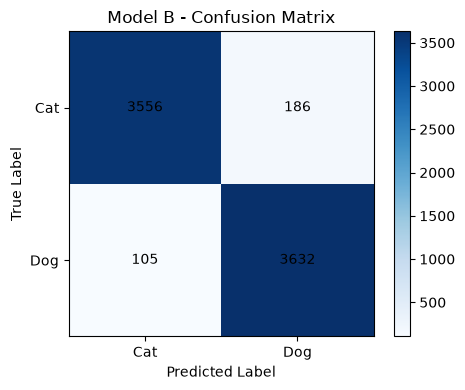

In [109]:
print(
    classification_report(

        y_true_B,

        y_pred_B,

        target_names=[
            "Cat",
            "Dog"
        ]
    )
)

cm_B = confusion_matrix(
    y_true_B,
    y_pred_B
)


plt.figure(
    figsize=(5, 4)
)

plt.imshow(
    cm_B,
    cmap="Blues"
)

plt.title(
    "Model B - Confusion Matrix"
)

plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.xticks(
    [0, 1],
    ["Cat", "Dog"]
)

plt.yticks(
    [0, 1],
    ["Cat", "Dog"]
)


for i in range(2):

    for j in range(2):

        plt.text(
            j,
            i,
            cm_B[i, j],
            ha="center",
            va="center"
        )


plt.colorbar()
plt.tight_layout()
plt.show()

Model A vs Model B Comparison

In [110]:
# ================================================================
# 50. MODEL A VS MODEL B
# ================================================================

comparison_results = pd.DataFrame({

    "Model": [
        "Model A",
        "Model B"
    ],

    "Input": [

        "Original images resized to 128x128",

        "32x32 images enhanced to 128x128 using SRGAN"
    ],

    "Accuracy": [
        model_A_accuracy,
        model_B_accuracy
    ],

    "Precision": [
        model_A_precision,
        model_B_precision
    ],

    "Recall": [
        model_A_recall,
        model_B_recall
    ],

    "F1 Score": [
        model_A_f1,
        model_B_f1
    ],

    "AUC": [
        model_A_auc,
        model_B_auc
    ],

    "Loss": [
        model_A_loss,
        model_B_loss
    ]

})


comparison_results

,Model,Input,Accuracy,Precision,Recall,F1 Score,AUC,Loss
0,Model A,Original images resized to 128x128,0.980746,0.982541,0.978860,0.980697,0.998353,0.061560
1,Model B,32x32 images enhanced to 128x128 using SRGAN,0.961091,0.951283,0.971903,0.961482,0.994540,0.109761


In [111]:
comparison_path = (
    PROJECT_DIR /
    "Model_A_vs_Model_B.csv"
)


comparison_results.to_csv(
    comparison_path,
    index=False
)


print(
    "Comparison saved:",
    comparison_path
)

Comparison saved: /home/sjainab/Assignments AAI/Assignment 3/Applied_AI_Midterm/Model_A_vs_Model_B.csv
